# Verification of the firn model

This notebook tests the **same simulation code** used by the web application (the `firnmodel`
package), with no user interface involved. It contains three tests:

1. **Heat equation vs. analytical solution** (the main test of the PDE solver): a seasonal temperature
   wave in a homogeneous medium, with convergence in grid spacing $\Delta z$ and time step $\Delta t$.
2. **Densification vs. analytical steady state**: the Herron–Langway steady-state density profile.
3. **Water mass conservation** in the full coupled model with melt, refreezing and ponding.

The full application (melt, refreezing, ponding, warming) has no analytical solution; these simplified
cases verify the components it is built from, by switching parts of the model off through its parameters.

In [1]:
import os, sys, math, time
sys.path.insert(0, os.path.abspath(".."))   # repository root, so firnmodel can be imported

import numpy as np
import matplotlib.pyplot as plt

import firnmodel
from firnmodel.heat import conductivity
from firnmodel.densification import steady_state_density
from firnmodel.params import C_ICE, DAYS_PER_YEAR, SECONDS_PER_DAY

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("firnmodel version", firnmodel.__version__, "| numpy", np.__version__)

firnmodel version 1.0.0 | numpy 2.5.3


## Test 1: Seasonal temperature wave

### Test problem

With meltwater, densification and accumulation switched off and a uniform density, the model's
heat equation

$$\rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial z}\left(k(\rho)\frac{\partial T}{\partial z}\right) + L R$$

reduces to the constant-coefficient diffusion equation (no refreezing, so $R = 0$):

$$\frac{\partial T}{\partial t} = \kappa \frac{\partial^2 T}{\partial z^2}, \qquad \kappa = \frac{k}{\rho c}.$$

The model's surface forcing is $T_s(t) = T_{mean} - A\cos\big(\omega (t - t_0)\big)$ with
$\omega = 2\pi / (1\ \text{year})$. For a half-space $z \ge 0$, the periodic solution is the damped,
phase-lagged seasonal wave (Carslaw and Jaeger, 1959):

$$T(z,t) = T_{mean} - A\, e^{-z/d} \cos\!\left(\omega (t - t_0) - \frac{z}{d}\right), \qquad d = \sqrt{\frac{2\kappa}{\omega}}.$$

The amplitude decays by a factor $e$ every damping depth $d$, and the phase lags by one radian per $d$.

### Matching parameters, initial and boundary conditions

| | Analytical problem | Model setting |
|---|---|---|
| Density | uniform $\rho = 500$ kg m⁻³ | `initial_density = 500`, `enable_densification = False` |
| Conductivity | $k(\rho)$ from Calonne et al. (2011) | same function, `firnmodel.heat.conductivity` |
| Surface (z = 0) | $T_s(t)$ above | `T_mean = -15`, `T_amp = 10`, `coldest_day = 15`; $T_s < 0$ always, so no melt |
| Base | half-space ($z \to \infty$) | zero-flux base at $H = 30$ m $\approx 12\,d$ |
| Initial condition | — | the analytical solution at $t = 0$ (so the error is purely numerical) |
| Other processes | none | `enable_melt = False`, `enable_accumulation = False` |

The zero-flux base differs from the half-space, but the analytical heat flux at 30 m is
$\sim e^{-12}$ of its surface value, so this adds an error far below the discretization error.

In [2]:
RHO = 500.0                 # kg m^-3
T_MEAN, AMP, T0 = -15.0, 10.0, 15.0   # deg C, deg C, day of the minimum
H = 30.0                    # m

k = float(conductivity(RHO))
kappa = k / (RHO * C_ICE)
omega = 2 * math.pi / (DAYS_PER_YEAR * SECONDS_PER_DAY)
d = math.sqrt(2 * kappa / omega)
print(f"k = {k:.3f} W/m/K,  kappa = {kappa:.3e} m^2/s,  damping depth d = {d:.2f} m,  H/d = {H/d:.1f}")

def exact(z, t_days):
    # Analytical seasonal wave [deg C] at depth z [m] and time t [days].
    return T_MEAN - AMP * np.exp(-z / d) * np.cos(omega * (t_days - T0) * SECONDS_PER_DAY - z / d)

BASE = dict(T_mean=T_MEAN, T_amp=AMP, warming_per_decade=0.0, coldest_day=T0,
            enable_melt=False, enable_densification=False, enable_accumulation=False,
            initial_density=RHO, depth=H, years=1.0)

def run_test(dz, dt_days, theta=0.5, years=1.0, snapshot_every_days=73.0):
    # Run the model on the test problem; return results and the RMS error at the final time.
    r = firnmodel.run(dict(BASE, dz=dz, dt_days=dt_days, theta=theta, years=years,
                           snapshot_every_days=snapshot_every_days),
                      T_init=lambda z: exact(z, 0.0))
    f = r["final"]
    t_final = r["series"]["t_years"][-1] * DAYS_PER_YEAR
    err = f["T"] - exact(f["z_centers"], t_final)
    return r, math.sqrt(np.mean(err**2)), np.abs(err).max()

k = 0.588 W/m/K,  kappa = 5.849e-07 m^2/s,  damping depth d = 2.42 m,  H/d = 12.4


### Run the simulation and compare with the analytical solution

dz = 0.25 m, dt = 1 day (the app's defaults): RMS error after 1 year = 3.03e-03 degC, max = 1.13e-02 degC


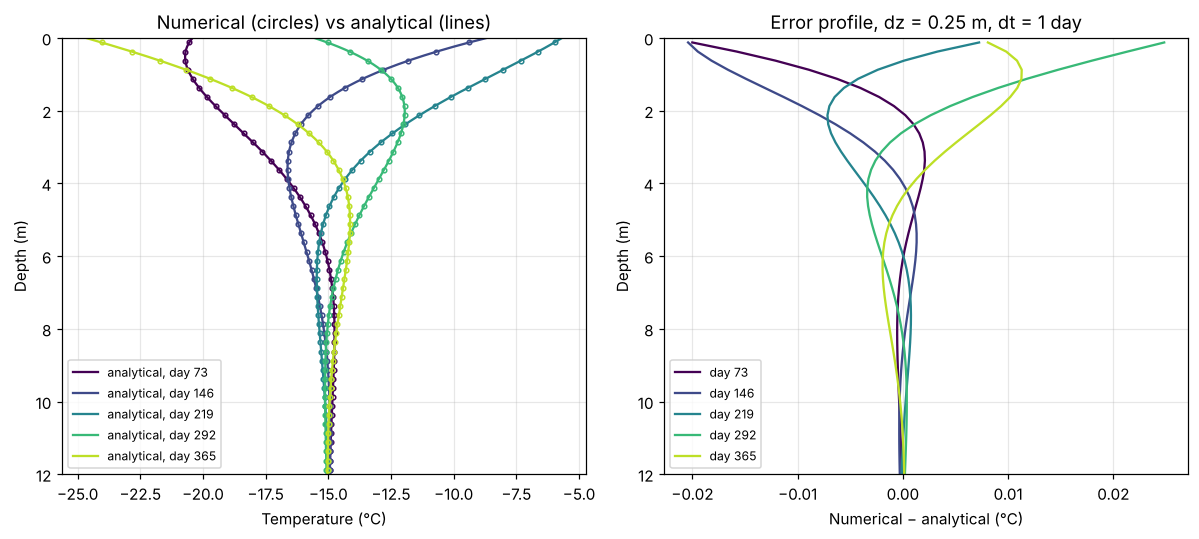

In [3]:
res, rms, mx = run_test(dz=0.25, dt_days=1.0)
print(f"dz = 0.25 m, dt = 1 day (the app's defaults): RMS error after 1 year = {rms:.2e} degC, max = {mx:.2e} degC")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
for snap, c in zip(res["snapshots"][1:6], colors):
    edges = snap["z_edges"]; zc = 0.5 * (edges[:-1] + edges[1:])
    t_days = snap["t_years"] * DAYS_PER_YEAR
    zf = np.linspace(0, 12, 300)
    axes[0].plot(exact(zf, t_days), zf, color=c, lw=1.5, label=f"analytical, day {t_days:.0f}")
    axes[0].plot(snap["T"], zc, "o", ms=3, color=c, mfc="none")
    axes[1].plot(snap["T"] - exact(zc, t_days), zc, color=c, label=f"day {t_days:.0f}")
axes[0].set(xlabel="Temperature (°C)", ylabel="Depth (m)", ylim=(12, 0),
            title="Numerical (circles) vs analytical (lines)")
axes[0].legend(fontsize=8)
axes[1].set(xlabel="Numerical − analytical (°C)", ylabel="Depth (m)", ylim=(12, 0),
            title="Error profile, dz = 0.25 m, dt = 1 day")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The numerical temperatures fall on the analytical curves at every time: the seasonal wave decays with
depth and its phase lags, exactly as predicted. Errors are of order $10^{-3}$ °C, largest in the upper
few metres where the curvature $\partial^2 T/\partial z^2$ is largest.

**Error measure.** We use the root-mean-square error over all layers at the final time,

$$E = \sqrt{\frac{1}{N}\sum_{i=1}^{N}\left(T_i^{\text{num}} - T^{\text{exact}}(z_i, t_{\text{final}})\right)^2},$$

and the observed order of convergence between two refinements, $p = \ln(E_1/E_2) / \ln(\Delta_1/\Delta_2)$.

### Convergence with grid spacing

The time step is made very small ($\Delta t = 0.05$ day) so the time error is negligible, and $\Delta z$
is halved repeatedly. Crank–Nicolson with central differences is second order in space, so we expect
$E \propto \Delta z^2$, i.e. $p \approx 2$.

In [4]:
dz_list = [0.8, 0.4, 0.2, 0.1, 0.05]
E_dz = []
for dz in dz_list:
    _, e, _ = run_test(dz=dz, dt_days=0.05)
    E_dz.append(e)

print(f"{'dz (m)':>8} {'RMS error (degC)':>18} {'order p':>8}")
for i, (dz, e) in enumerate(zip(dz_list, E_dz)):
    p = "" if i == 0 else f"{math.log(E_dz[i-1] / e) / math.log(dz_list[i-1] / dz):8.2f}"
    print(f"{dz:8.3f} {e:18.3e} {p}")

  dz (m)   RMS error (degC)  order p
   0.800          3.099e-02 
   0.400          7.755e-03     2.00
   0.200          1.926e-03     2.01
   0.100          4.807e-04     2.00
   0.050          1.203e-04     2.00


### Convergence with time step

Now $\Delta z = 0.025$ m is fine enough that the spatial error is small, and $\Delta t$ is halved
repeatedly (step sizes that divide one year exactly). Crank–Nicolson ($\theta = 0.5$) should be second
order in time; backward Euler ($\theta = 1$), also available in the app, should be first order.

In [5]:
dt_list = [365 / 10, 365 / 20, 365 / 40, 365 / 80, 365 / 160]
E_cn, E_be = [], []
for dt in dt_list:
    E_cn.append(run_test(dz=0.025, dt_days=dt, theta=0.5)[1])
    E_be.append(run_test(dz=0.025, dt_days=dt, theta=1.0)[1])

print(f"{'dt (days)':>10} {'CN error':>12} {'order':>6} {'BE error':>12} {'order':>6}")
for i, dt in enumerate(dt_list):
    if i == 0:
        print(f"{dt:10.2f} {E_cn[i]:12.3e} {'':>6} {E_be[i]:12.3e}")
    else:
        r = dt_list[i-1] / dt
        print(f"{dt:10.2f} {E_cn[i]:12.3e} {math.log(E_cn[i-1]/E_cn[i])/math.log(r):6.2f} "
              f"{E_be[i]:12.3e} {math.log(E_be[i-1]/E_be[i])/math.log(r):6.2f}")

 dt (days)     CN error  order     BE error  order
     36.50    2.466e-02           1.544e-01
     18.25    6.091e-03   2.02    8.299e-02   0.90
      9.12    1.537e-03   1.99    4.316e-02   0.94
      4.56    4.038e-04   1.93    2.202e-02   0.97
      2.28    1.215e-04   1.73    1.112e-02   0.99


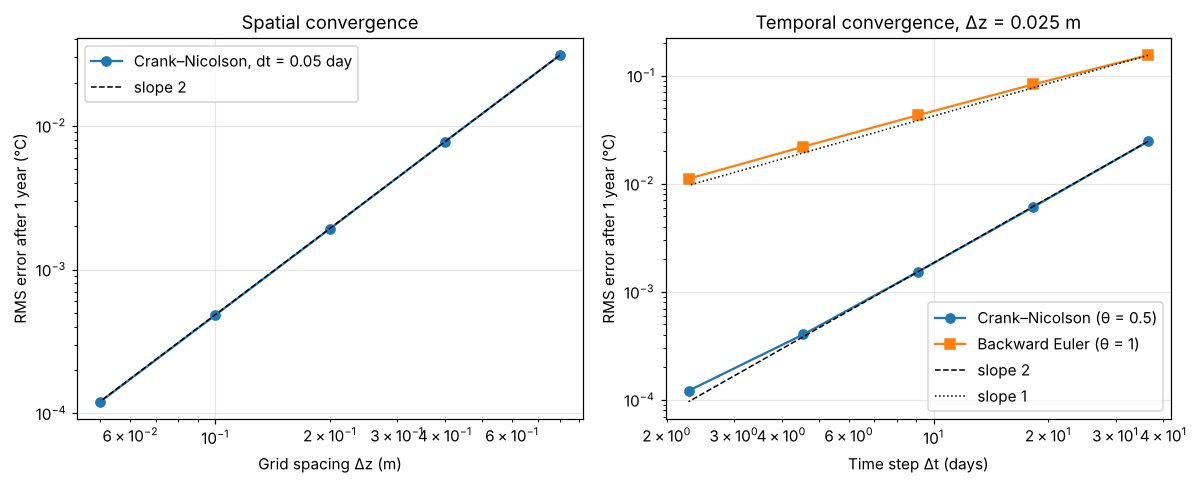

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
dz_arr = np.array(dz_list)
axes[0].loglog(dz_arr, E_dz, "o-", label="Crank–Nicolson, dt = 0.05 day")
axes[0].loglog(dz_arr, E_dz[0] * (dz_arr / dz_arr[0])**2, "k--", lw=1, label="slope 2")
axes[0].set(xlabel="Grid spacing Δz (m)", ylabel="RMS error after 1 year (°C)", title="Spatial convergence")
axes[0].legend()

dt_arr = np.array(dt_list)
axes[1].loglog(dt_arr, E_cn, "o-", label="Crank–Nicolson (θ = 0.5)")
axes[1].loglog(dt_arr, E_be, "s-", label="Backward Euler (θ = 1)")
axes[1].loglog(dt_arr, E_cn[0] * (dt_arr / dt_arr[0])**2, "k--", lw=1, label="slope 2")
axes[1].loglog(dt_arr, E_be[0] * (dt_arr / dt_arr[0]), "k:", lw=1, label="slope 1")
axes[1].set(xlabel="Time step Δt (days)", ylabel="RMS error after 1 year (°C)",
            title="Temporal convergence, Δz = 0.025 m")
axes[1].legend()
plt.tight_layout(); plt.show()

### Discussion of Test 1

* **Agreement.** The solver reproduces the amplitude decay and phase lag of the seasonal wave. At the
  resolution used in the app ($\Delta z = 0.25$ m, $\Delta t = 1$ day) the RMS error is about
  $10^{-3}$ °C, against a surface amplitude of 10 °C.
* **Spatial convergence** is second order ($p \approx 2.0$). This includes the surface boundary, where
  the Dirichlet temperature sits half a layer above the first cell centre.
* **Temporal convergence** is second order for Crank–Nicolson and first order for backward Euler, as
  theory predicts. At the smallest $\Delta t$ the Crank–Nicolson order drops below 2 because the
  error approaches the fixed spatial error of the $\Delta z = 0.025$ m grid; the two error sources
  add, and the spatial one no longer shrinks.
* **Limitations.** This test uses constant properties. In the application, conductivity varies with
  density, and the variable-coefficient discretization (series conductances between layers) is not
  tested against an exact solution here. Crank–Nicolson is unconditionally stable but not monotone: for
  $\kappa\Delta t/\Delta z^2 \gg 1$ (here about 0.8 at the app defaults, but larger for thin surface
  layers) sudden changes in surface temperature can produce small decaying oscillations. Backward Euler
  avoids them at the cost of first-order accuracy. The zero-flux base is an approximation to the
  half-space whose error is negligible at $H \approx 12d$.

## Test 2: Densification steady state

With constant temperature and accumulation $b$, firn moves down at $v = b\rho_w/\rho$ and the Herron–Langway
rate $d\rho/dt = C(\rho_i - \rho)$ gives a steady profile satisfying $v\, d\rho/dz = C(\rho_i - \rho)$. In each
stage this integrates to a logistic curve:

$$\ln\frac{\rho}{\rho_i - \rho} = \ln\frac{\rho_0}{\rho_i - \rho_0} + \frac{\rho_i c_0}{\rho_w} z \quad (\rho < 550), \qquad
\ln\frac{\rho}{\rho_i - \rho} = \ln\frac{550}{\rho_i - 550} + \frac{\rho_i c_1}{\rho_w \sqrt{b}}(z - z_{550}) \quad (\rho \ge 550).$$

**Setup:** $T = -20$ °C everywhere and constant (`T_amp = 0`, no melt), $b = 0.3$ m w.e./yr, fresh snow
$\rho_0 = 350$ kg m⁻³. The model starts from a *uniform* 350 kg m⁻³ column (not the steady state) and runs
150 years, so the steady profile has to be built by burial, densification and regridding in the model.
This tests the densification ODE, the moving (Lagrangian) grid and the accumulation of new layers together.

 dz (m)  RMS error (kg/m3)  max error


   0.50              0.812      7.734


   0.25              0.244      2.694


   0.10              0.170      1.290


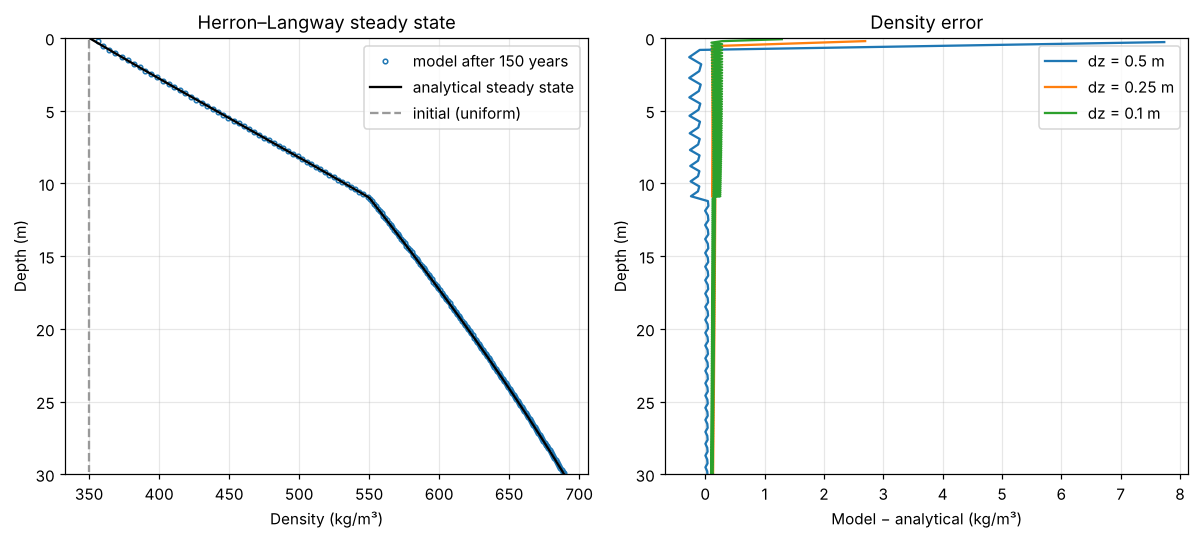

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
print(f"{'dz (m)':>7} {'RMS error (kg/m3)':>18} {'max error':>10}")
for dz in [0.5, 0.25, 0.1]:
    r = firnmodel.run(dict(T_mean=-20.0, T_amp=0.0, warming_per_decade=0.0, enable_melt=False,
                           accumulation=0.3, rho_snow=350.0, initial_density=350.0,
                           dz=dz, dt_days=10.0, years=150.0, snapshot_every_days=3650.0))
    f = r["final"]
    rho_exact = steady_state_density(f["z_centers"], -20.0, 0.3, 350.0)
    err = f["rho"] - rho_exact
    print(f"{dz:7.2f} {math.sqrt(np.mean(err**2)):18.3f} {np.abs(err).max():10.3f}")
    axes[1].plot(err, f["z_centers"], label=f"dz = {dz} m")
    if dz == 0.25:
        axes[0].plot(f["rho"], f["z_centers"], "o", ms=3, mfc="none", label="model after 150 years")
        zf = np.linspace(0, 30, 300)
        axes[0].plot(steady_state_density(zf, -20.0, 0.3, 350.0), zf, "k-", label="analytical steady state")
        axes[0].plot(r["initial"]["rho"], 0.5 * (r["initial"]["z_edges"][1:] + r["initial"]["z_edges"][:-1]),
                     color="0.6", ls="--", label="initial (uniform)")
axes[0].set(xlabel="Density (kg/m³)", ylabel="Depth (m)", ylim=(30, 0), title="Herron–Langway steady state")
axes[0].legend()
axes[1].set(xlabel="Model − analytical (kg/m³)", ylabel="Depth (m)", ylim=(30, 0), title="Density error")
axes[1].legend()
plt.tight_layout(); plt.show()

The model builds the analytical steady-state profile from a uniform start, with RMS errors below
1 kg m⁻³ that decrease as the layers get thinner. The largest error is in the top layer, where each
day's new snow is mixed into a layer that is already slightly denser. The small sawtooth above 11 m
(clearest for $\Delta z = 0.5$ m) comes from the same cause: the top layer grows by daily snowfall until
it is split in two, so successive layers start densifying from slightly different states.

## Test 3: Water mass conservation in the full model

The coupled model with melt, refreezing, perched water and ponds has no analytical solution, but water
must be conserved exactly:

$$\text{melt} = \text{liquid water stored} + \text{pond} + \text{refrozen} + \text{runoff} + \text{lateral flow} + \text{deep drainage}.$$

The scenarios below are the app's presets; the default is the one shown in the app on loading.

In [8]:
scenarios = {
    "Warming: slab, then ponds (app default)": {},
    "Percolation zone":            dict(T_mean=-14.0, warming_per_decade=0.0, years=30.0),
    "Runoff zone with lakes":      dict(T_mean=-10.0, T_amp=14.0, warming_per_decade=0.0, years=30.0),
}
print(f"{'scenario':42s} {'melt (mm w.e.)':>14} {'refrozen':>9} {'runoff':>7} {'max pond (m)':>12} {'relative balance error':>22}")
for name, values in scenarios.items():
    s = firnmodel.run(values)["summary"]
    print(f"{name:42s} {s['total_melt']:14.0f} {s['refrozen_fraction']:9.0%} {s['runoff_fraction']:7.0%} "
          f"{s['pond_max']:12.2f} {s['mass_balance_relative_error']:22.1e}")

scenario                                   melt (mm w.e.)  refrozen  runoff max pond (m) relative balance error


Warming: slab, then ponds (app default)              8911       63%     37%         0.20                6.1e-16


Percolation zone                                     4257      100%      0%         0.00                1.5e-15


Runoff zone with lakes                              35654       29%     56%         0.33                1.6e-15


Water is conserved to rounding error (~$10^{-15}$) in every scenario, so no water is created or lost by
the percolation, refreezing, ponding and regridding steps.

## Summary and limitations

* The heat-equation solver (Crank–Nicolson finite volumes, Thomas algorithm) matches the analytical
  seasonal wave and converges at second order in both $\Delta z$ and $\Delta t$; backward Euler
  converges at first order in time.
* The densification model and the moving grid reproduce the analytical steady-state density profile.
* The coupled model conserves water to machine precision.

What these tests do **not** verify: the meltwater physics itself (bucket percolation, irreducible water,
the impermeable density threshold, degree-day melt and pond freezing) is a set of simplified rules chosen
from the literature, so its realism can only be judged against observations, not against an exact
solution. The coupling between processes uses operator splitting (each process sees the others' values
from the start of the step); its error shrinks with $\Delta t$. Halving the time step from 1 to 0.5 day
changes the default scenario's melt, refreezing and first pond year by less than 0.2% and its final
ice-slab thickness by about 6%.